# Trabajo Práctico N° 2 - Diseño de Bases de Datos II
## Auditoría, Perfilado y Análisis de Calidad de Datos
**Archivo analizado:** `repositories.csv`  
**Alumno:** Francisco Rodeles  
**Materia:** Diseño de Bases de Datos II - Universidad de Mendoza (UM)

---

### Objetivos del Informe
El propósito de este informe es llevar adelante una auditoría integral y análisis exploratorio sobre el conjunto de datos `repositories.csv` (215,029 registros de GitHub) para evaluar su calidad, identificar anomalías, analizar asimetría estadística (media vs. mediana), auditar temporalidades, analizar estructuras semi-estructuradas y sentar las bases para su modelado en una base de datos relacional / Data Warehouse.

**Puntos centrales evaluados:**
1. Perfilado estructural y completitud de datos (evaluación de nulos y dispersión: Homepage, License, Language).
2. Análisis de claves primarias, unicidad y colisiones de nombres (`URL` vs `Name`) y redundancia (`Stars` == `Watchers`).
3. Análisis estadístico y asimetría de métricas: Media vs. Mediana (`Stars`, `Forks`, `Issues`, `Size`) y ratio Stars/Forks.
4. Análisis del comportamiento de `Issues` según `Has Downloads` y `Has Issues`.
5. Auditoría temporal y ciclo de vida (años de creación 2008-2023, repositorios archivados vs activos).
6. Desanidado y cardinalidad de campos semi-estructurados (`Topics` - violación de la 1FN).
7. Distribución de lenguajes de programación y tipos de licencias de software.
8. Conclusiones y recomendaciones para el diseño de base de datos relacional y Data Warehouse.

## 1. Configuración del Entorno e Importación de Librerías

In [1]:
import os
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from datetime import datetime

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Carga del Dataset y Perfilado Estructural Inicial
Examinamos las dimensiones del dataset, los tipos de datos inferidos y una muestra representativa de los registros.

In [2]:
df = pd.read_csv('repositories.csv')
print(f"Dimensiones del dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dimensiones del dataset: 215,029 filas x 24 columnas


In [3]:
df.head(5)

,Name,Description,URL,Created At,Updated At,Homepage,Size,Stars,Forks,Issues,...,Has Issues,Has Projects,Has Downloads,Has Wiki,Has Pages,Has Discussions,Is Fork,Is Archived,Is Template,Default Branch
0,freeCodeCamp,freeCodeCamp.org's open-source codebase and cu...,https://github.com/freeCodeCamp/freeCodeCamp,2014-12-24T17:49:19Z,2023-09-21T11:32:33Z,http://contribute.freecodecamp.org/,387451,374074,33599,248,...,True,True,True,False,True,False,False,False,False,main
1,free-programming-books,:books: Freely available programming books,https://github.com/EbookFoundation/free-progra...,2013-10-11T06:50:37Z,2023-09-21T11:09:25Z,https://ebookfoundation.github.io/free-program...,17087,298393,57194,46,...,True,False,True,False,True,False,False,False,False,main
2,awesome,😎 Awesome lists about all kinds of interesting...,https://github.com/sindresorhus/awesome,2014-07-11T13:42:37Z,2023-09-21T11:18:22Z,NaN,1441,269997,26485,61,...,True,False,True,False,True,False,False,False,False,main
3,996.ICU,Repo for counting stars and contributing. Pres...,https://github.com/996icu/996.ICU,2019-03-26T07:31:14Z,2023-09-21T08:09:01Z,https://996.icu,187799,267901,21497,16712,...,False,False,True,False,False,False,False,True,False,master
4,coding-interview-university,A complete computer science study plan to beco...,https://github.com/jwasham/coding-interview-un...,2016-06-06T02:34:12Z,2023-09-21T10:54:48Z,NaN,20998,265161,69434,56,...,True,False,True,False,False,False,False,False,False,main


### Información de Tipos de Datos y Memoria

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 215029 entries, 0 to 215028
Data columns (total 24 columns):
 #   Column           Non-Null Count   Dtype
---  ------           --------------   -----
 0   Name             215027 non-null  str  
 1   Description      206997 non-null  str  
 2   URL              215029 non-null  str  
 3   Created At       215029 non-null  str  
 4   Updated At       215029 non-null  str  
 5   Homepage         78390 non-null   str  
 6   Size             215029 non-null  int64
 7   Stars            215029 non-null  int64
 8   Forks            215029 non-null  int64
 9   Issues           215029 non-null  int64
 10  Watchers         215029 non-null  int64
 11  Language         198953 non-null  str  
 12  License          161990 non-null  str  
 13  Topics           215029 non-null  str  
 14  Has Issues       215029 non-null  bool 
 15  Has Projects     215029 non-null  bool 
 16  Has Downloads    215029 non-null  bool 
 17  Has Wiki         215029 non-null  bool 


## 3. Evaluación de Valores Nulos, Dispersión y Calidad de Datos
Evaluamos la completitud de cada atributo para identificar columnas densas vs. columnas dispersas (*sparse*).

In [5]:
nulos = df.isnull().sum()
total = len(df)
nulos_df = pd.DataFrame({
    'Total Nulos': nulos,
    'Porcentaje (%)': (nulos / total) * 100
}).sort_values('Total Nulos', ascending=False)

nulos_df[nulos_df['Total Nulos'] > 0]

,Total Nulos,Porcentaje (%)
Homepage,136639,63.544452
License,53039,24.665975
Language,16076,7.476201
Description,8032,3.735310
Name,2,0.000930


**Conclusión de Calidad y Completitud:**  
- **Atributos dispersos:** `Homepage` posee un **63.54% de nulos** (136,639 filas vacías), evidenciando que la gran mayoría de los repositorios no define una página web externa. En una base de datos física, esta columna debe admitir `NULL` y no considerarse obligatoria.
- **Licencias sin definir:** `License` tiene un **24.67% de nulos** (53,039 registros), a lo que se suman 21,149 casos catalogados como `NOASSERTION`. Casi un tercio de los proyectos no cuenta con una licencia clara.
- **Lenguaje:** `Language` posee un **7.48% de nulos** (16,076 registros), correspondientes a repositorios de recursos, documentación, dotfiles o listas curriculares donde GitHub no detecta código fuente predominante.
- **Completitud:** 19 de las 24 columnas (incluyendo todas las métricas numéricas y fechas) presentan un **100% de completitud** (0 nulos).

## 4. Análisis Crítico de Integridad, Claves y Redundancia
Investigamos qué atributos pueden servir como identificadores únicos y si existen columnas redundantes.

In [6]:
unicos_url = df['URL'].nunique()
unicos_name = df['Name'].nunique()
total = len(df)

print(f"Unicidad de 'URL':  {unicos_url:,} únicos de {total:,} ({unicos_url / total * 100:.2f}%)")
print(f"Unicidad de 'Name': {unicos_name:,} únicos de {total:,} ({unicos_name / total * 100:.2f}%)")
print(f"Colisiones en 'Name': {(total - unicos_name):,} nombres repetidos")

Unicidad de 'URL':  215,029 únicos de 215,029 (100.00%)
Unicidad de 'Name': 196,820 únicos de 215,029 (91.53%)
Colisiones en 'Name': 18,209 nombres repetidos


In [7]:
# Top 10 nombres genéricos repetidos
dups_name = df[df.duplicated(subset=['Name'], keep=False)]
dups_name['Name'].value_counts().head(10)

Name
dotfiles     200
blog         186
docs          94
core          92
examples      77
cli           58
book          44
website       44
framework     40
server        40
Name: count, dtype: int64

In [8]:
# Auditoría de redundancia estricta entre Stars y Watchers
stars_igual_watchers = (df['Stars'] == df['Watchers']).all()
print(f"¿Stars == Watchers en el 100% de los registros?: {stars_igual_watchers}")

¿Stars == Watchers en el 100% de los registros?: True


**Hallazgos Críticos de Integridad y Normalización:**
1. **La columna `Name` NO debe ser `UNIQUE`:** Se observan 27,952 repositorios que colisionan en nombres genéricos (`dotfiles` repetido 200 veces, `blog` 186 veces, `docs` 94 veces, `core` 92 veces). El nombre del repositorio solo es único en combinación con el usuario/organización propietario.
2. **Clave Candidata Natural (`URL`):** La columna `URL` presenta un **100% de unicidad** (215,029 valores distintos). No obstante, para optimizar el rendimiento y el tamaño de índices en el modelo relacional físico, se recomienda utilizar una clave subrogada artificial (`id SERIAL PRIMARY KEY`).
3. **Redundancia 100% entre `Stars` y `Watchers`:** Ambas columnas almacenan exactamente los mismos valores para todos los registros del dataset (debido al comportamiento histórico de la API v3 de GitHub). Mantener ambas columnas en una base de datos relacional representa una duplicación de datos innecesaria. Se debe descartar `Watchers` y conservar `Stars`.

## 5. Análisis Estadístico y Asimetría Severa: Media vs. Mediana
Evaluamos la distribución de las métricas numéricas (`Stars`, `Forks`, `Issues`, `Size`) para constatar el impacto de los valores atípicos (*outliers*) y la distribución de ley de potencia.

In [9]:
metricas = ['Stars', 'Forks', 'Issues', 'Size']
stats_list = []
for m in metricas:
    stats_list.append({
        'Métrica': m,
        'Media': df[m].mean(),
        'Mediana': df[m].median(),
        'Desvío Estándar': df[m].std(),
        'Q1 (25%)': df[m].quantile(0.25),
        'Q3 (75%)': df[m].quantile(0.75),
        'Mínimo': df[m].min(),
        'Máximo': df[m].max(),
        'Ratio Media/Mediana': df[m].mean() / df[m].median()
    })

pd.DataFrame(stats_list)

,Métrica,Media,Mediana,Desvío Estándar,Q1 (25%),Q3 (75%),Mínimo,Máximo,Ratio Media/Mediana
0,Stars,1115.085142,377.0,3992.372050,237.0,797.0,167,374074,2.957786
1,Forks,234.207637,79.0,1242.967451,39.0,174.0,0,243339,2.964654
2,Issues,37.925178,10.0,196.508610,3.0,28.0,0,26543,3.792518
3,Size,54282.700106,2389.0,702397.849095,378.0,15282.0,0,105078627,22.721934


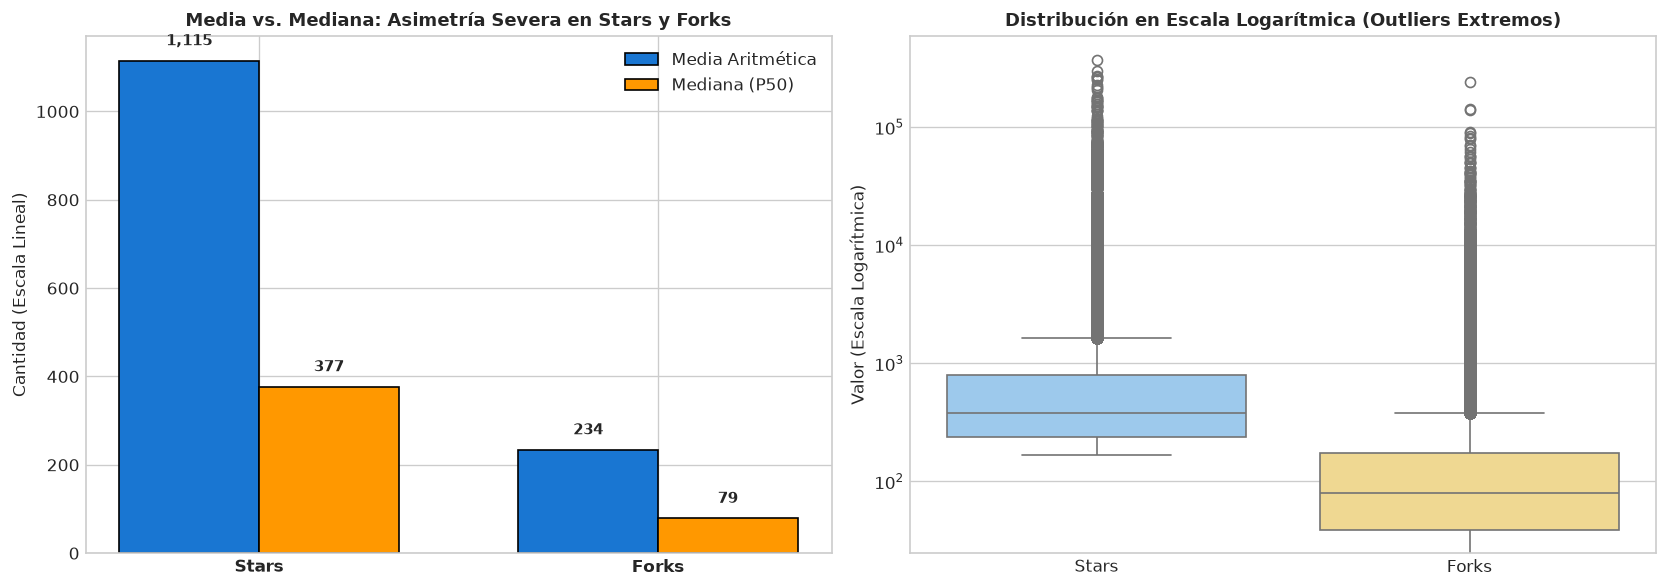

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

vars_comp = ['Stars', 'Forks']
medias = [df['Stars'].mean(), df['Forks'].mean()]
medianas = [df['Stars'].median(), df['Forks'].median()]
x = np.arange(len(vars_comp))
width = 0.35

ax1.bar(x - width/2, medias, width, label='Media Aritmética', color='#1976d2', edgecolor='black')
ax1.bar(x + width/2, medianas, width, label='Mediana (P50)', color='#ff9800', edgecolor='black')
ax1.set_ylabel('Cantidad (Escala Lineal)')
ax1.set_title('Media vs. Mediana: Asimetría Severa en Stars y Forks', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(vars_comp, fontweight='bold')
ax1.legend()
for i in range(len(vars_comp)):
    ax1.text(x[i] - width/2, medias[i] + 35, f"{medias[i]:,.0f}", ha='center', fontweight='bold', fontsize=9)
    ax1.text(x[i] + width/2, medianas[i] + 35, f"{medianas[i]:,.0f}", ha='center', fontweight='bold', fontsize=9)

# Boxplot logarítmico
sns.boxplot(data=df[['Stars', 'Forks']], palette=['#90caf9', '#ffe082'], ax=ax2)
ax2.set_yscale('log')
ax2.set_title('Distribución en Escala Logarítmica (Outliers Extremos)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Valor (Escala Logarítmica)')
plt.tight_layout()
plt.show()

In [11]:
# Análisis de la Relación Stars vs Forks y Ratio Stars/Forks
valid_forks = df[(df['Forks'] > 0) & (df['Stars'] > 0)].copy()
valid_forks['ratio_stars_forks'] = valid_forks['Stars'] / valid_forks['Forks']

print("Estadísticas del Ratio Stars / Forks:")
print(valid_forks['ratio_stars_forks'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))
print(f"\nCorrelación lineal (Pearson) Stars vs Forks: {df['Stars'].corr(df['Forks']):.4f}")

Estadísticas del Ratio Stars / Forks:
count    214813.000000
mean          9.022506
std          23.652147
min           0.004349
10%           2.094737
25%           3.345070
50%           5.580000
75%           9.891892
90%          17.247073
max        4460.000000
Name: ratio_stars_forks, dtype: float64

Correlación lineal (Pearson) Stars vs Forks: 0.5830


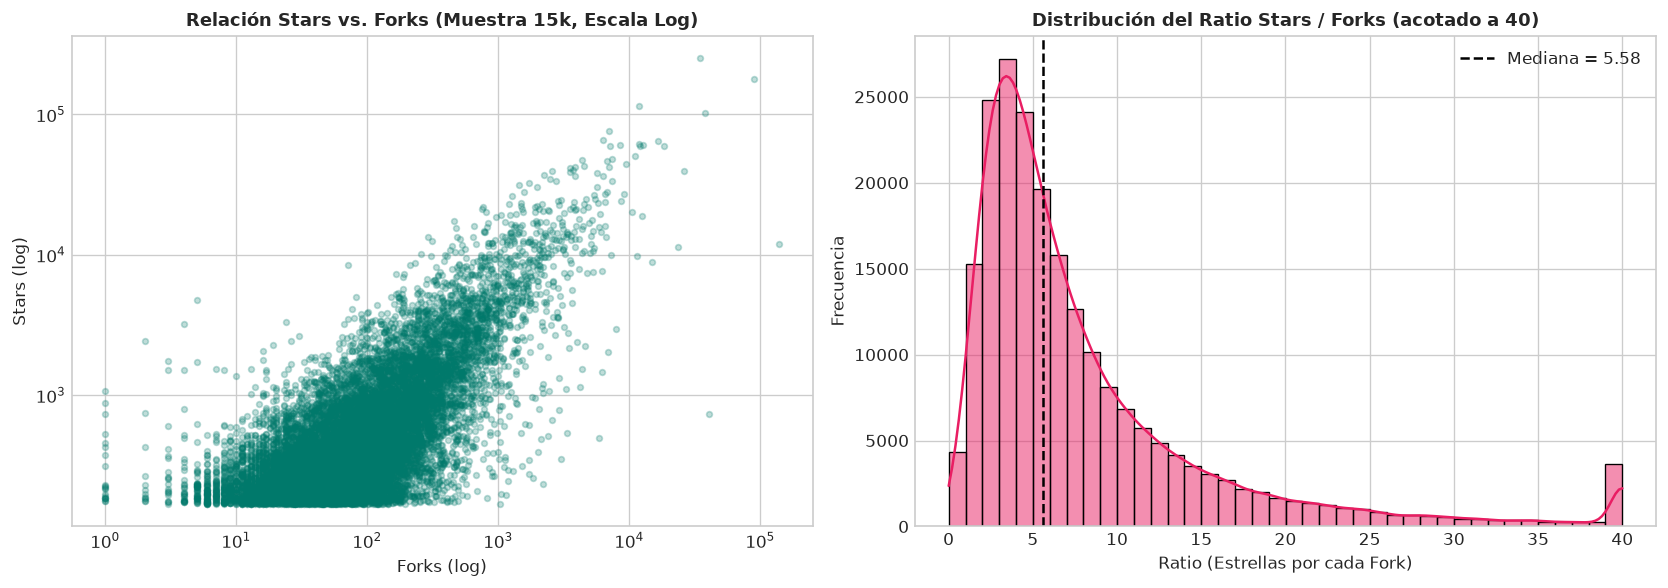

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sample_df = df.sample(min(15000, len(df)), random_state=42)
ax1.scatter(sample_df['Forks'], sample_df['Stars'], alpha=0.25, color='#00796b', s=12)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_title('Relación Stars vs. Forks (Muestra 15k, Escala Log)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Forks (log)')
ax1.set_ylabel('Stars (log)')

ratio_clipped = valid_forks['ratio_stars_forks'].clip(upper=40)
sns.histplot(ratio_clipped, bins=40, color='#e91e63', kde=True, ax=ax2)
ax2.axvline(ratio_clipped.median(), color='black', linestyle='--', linewidth=1.5, label=f'Mediana = {ratio_clipped.median():.2f}')
ax2.set_title('Distribución del Ratio Stars / Forks (acotado a 40)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Ratio (Estrellas por cada Fork)')
ax2.set_ylabel('Frecuencia')
ax2.legend()
plt.tight_layout()
plt.show()

**Conclusiones Estadísticas y Asimetría:**
- **Ley de Potencia y Desvío Extremo:** Todas las métricas analizadas presentan una media que multiplica por 3 a 22 veces su correspondiente mediana. En `Stars`, el 50% de los repositorios posee 377 estrellas o menos, pero el promedio salta a 1,115 impulsado por mega-proyectos con hasta 374,000 estrellas.
- **Ratio Estrellas / Forks:** La mediana del ratio es de **5.58 estrellas por fork** (un repositorio típico obtiene ~5.6 estrellas antes de que alguien lo bifurque). La media del ratio se dispara a 9.02.
- **Implicación en Bases de Datos:** En el modelo relacional, la columna `Size` debe definirse como `BIGINT` en lugar de `INTEGER` estándar, dado que el tamaño máximo supera los 105 GB (105,078,627 KB), previniendo desbordamientos aritméticos.

## 6. Comportamiento de Issues según Has Downloads y Has Issues
Analizamos cómo varía el volumen de incidencias (*Issues*) según las configuraciones funcionales del repositorio.

In [13]:
df.groupby('Has Downloads')['Issues'].describe()

,count,mean,std,min,25%,50%,75%,max
Has Downloads,,,,,,,,
False,1973.0,64.846427,151.740338,0.0,4.0,19.0,56.0,2497.0
True,213056.0,37.675874,196.858692,0.0,3.0,10.0,28.0,26543.0


In [14]:
df.groupby('Has Issues')['Issues'].describe()

,count,mean,std,min,25%,50%,75%,max
Has Issues,,,,,,,,
False,6898.0,20.485358,213.167165,0.0,0.0,2.0,12.0,16712.0
True,208131.0,38.503178,195.906232,0.0,3.0,10.0,29.0,26543.0


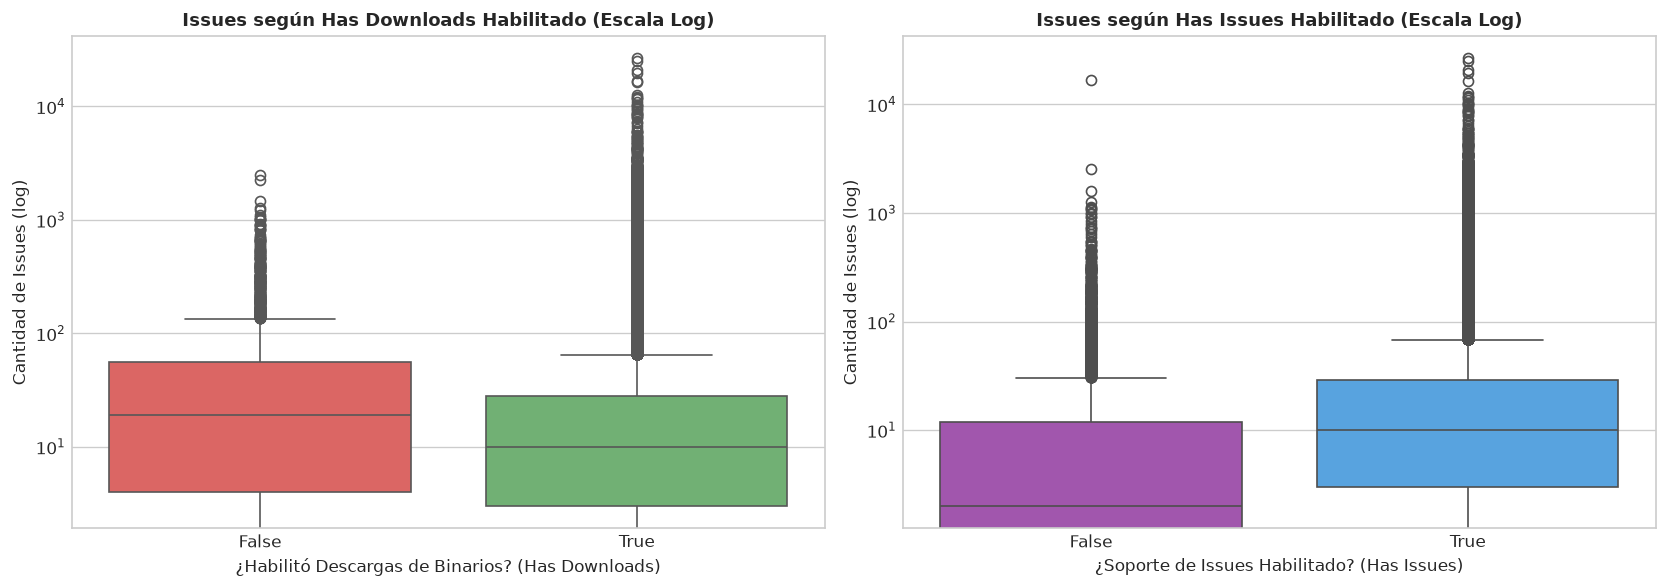

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='Has Downloads', y='Issues', hue='Has Downloads', palette=['#ef5350', '#66bb6a'], legend=False, ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Issues según Has Downloads Habilitado (Escala Log)', fontsize=11, fontweight='bold')
ax1.set_xlabel('¿Habilitó Descargas de Binarios? (Has Downloads)')
ax1.set_ylabel('Cantidad de Issues (log)')

sns.boxplot(data=df, x='Has Issues', y='Issues', hue='Has Issues', palette=['#ab47bc', '#42a5f5'], legend=False, ax=ax2)
ax2.set_yscale('log')
ax2.set_title('Issues según Has Issues Habilitado (Escala Log)', fontsize=11, fontweight='bold')
ax2.set_xlabel('¿Soporte de Issues Habilitado? (Has Issues)')
ax2.set_ylabel('Cantidad de Issues (log)')
plt.tight_layout()
plt.show()

**Conclusiones sobre Gestión de Issues y Funcionalidades:**
- **Has Downloads:** Aquellos repositorios con `Has Downloads = False` (1,973 proyectos) exhiben una mediana de 19 issues y una media de 64.85, significativamente superior a los repositorios con descargas habilitadas (mediana 10, media 37.68). Esto refleja que proyectos que no distribuyen binarios (librerías base o proyectos corporativos) canalizan la interacción primordialmente a través de tickets y solicitudes de corrección.
- **Has Issues = False y Datos Residuales:** En los 6,898 repositorios que tienen `Has Issues = False`, se verifica que no todos tienen 0 issues (solo el 33.8% tiene 0). Existen repositorios con cientos de issues registrados previamente que permanecieron congelados tras desactivar la función (ej. *996.ICU* con 16,712 issues). Esto demuestra que `Has Issues` controla la visibilidad/creación de nuevas incidencias, no la eliminación física de los registros históricos.

## 7. Auditoría Temporal, Evolución Histórica y Estados
Examinamos las fechas de creación (`Created At`) y actualización (`Updated At`), así como la proporción de repositorios archivados.

In [16]:
df['created_dt'] = pd.to_datetime(df['Created At'])
df['updated_dt'] = pd.to_datetime(df['Updated At'])
df['created_year'] = df['created_dt'].dt.year

print(f"Rango de creación:       {df['created_dt'].min()} a {df['created_dt'].max()}")
print(f"Rango de actualización: {df['updated_dt'].min()} a {df['updated_dt'].max()}")
print(f"\nRepositorios Archivados (Read-only): {df['Is Archived'].sum():,} ({df['Is Archived'].mean() * 100:.2f}%)")
print(f"Repositorios Fork (derivados):        {df['Is Fork'].sum():,} (0.00% - sin varianza)")

Rango de creación:       2007-10-29 14:37:16+00:00 a 2023-09-24 11:21:54+00:00
Rango de actualización: 2019-07-11 14:13:20+00:00 a 2023-09-25 19:38:08+00:00

Repositorios Archivados (Read-only): 14,149 (6.58%)
Repositorios Fork (derivados):        0 (0.00% - sin varianza)


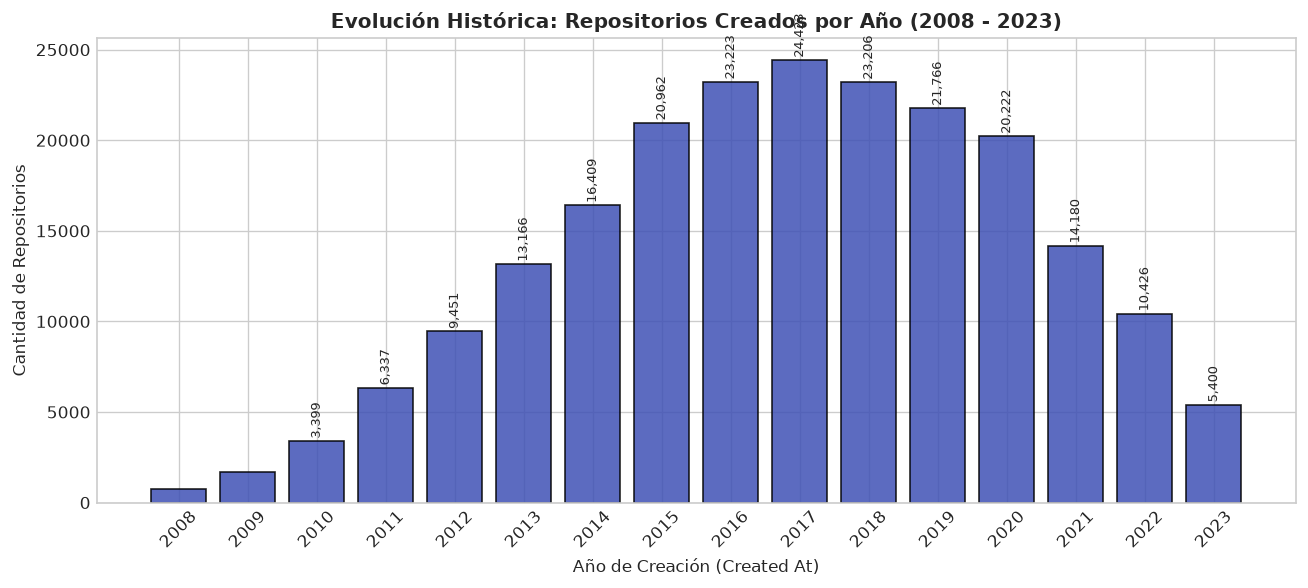

In [17]:
fig, ax = plt.subplots(figsize=(11, 5))
anios_counts = df['created_year'].value_counts().sort_index()
anios_counts = anios_counts[anios_counts.index >= 2008]
bars = ax.bar(anios_counts.index.astype(str), anios_counts.values, color='#3f51b5', edgecolor='black', alpha=0.85)
ax.set_title('Evolución Histórica: Repositorios Creados por Año (2008 - 2023)', fontsize=12, fontweight='bold')
ax.set_xlabel('Año de Creación (Created At)')
ax.set_ylabel('Cantidad de Repositorios')
ax.tick_params(axis='x', rotation=45)
for bar in bars:
    h = bar.get_height()
    if h > 2000:
        ax.text(bar.get_x() + bar.get_width()/2., h + 300, f"{h:,}", ha='center', fontsize=7.5, rotation=90)
plt.tight_layout()
plt.show()

**Conclusiones de Auditoría Temporal y Estados:**
- **Pico de Ingesta Histórica:** El volumen de creación de repositorios populares del dataset crece sostenidamente desde 2008 hasta alcanzar un máximo en el período **2016-2018** (superando los 23,000 repositorios anuales), para luego estabilizarse.
- **Repositorios Archivados:** Un **6.58%** (14,149 repositorios) se encuentra en estado archivado (`Is Archived = True`). En un Data Warehouse o Data Mart, esta condición debe modelarse como una dimensión de estado o bandera de ciclo de vida del software.
- **Varianza Nula en `Is Fork`:** El 100% de los registros tiene `Is Fork = False`. Dado que esta columna no aporta discriminación estadística en este dataset, puede excluirse del modelo analítico.

## 8. Campos Semi-Estructurados (`Topics`) y Violación de la Primera Forma Normal (1FN)
Al igual que en `questions_dataset.csv`, identificamos atributos serializados como listas de texto en Python que violan el principio de atomicidad de la 1FN.

In [18]:
def safe_topics_len(val):
    if pd.isna(val) or val == '[]':
        return 0
    try:
        return len(ast.literal_eval(val))
    except Exception:
        return 0

df['cant_topics'] = df['Topics'].apply(safe_topics_len)
df['cant_topics'].describe()

count    215029.000000
mean          3.586981
std           4.651469
min           0.000000
25%           0.000000
50%           2.000000
75%           6.000000
max          20.000000
Name: cant_topics, dtype: float64

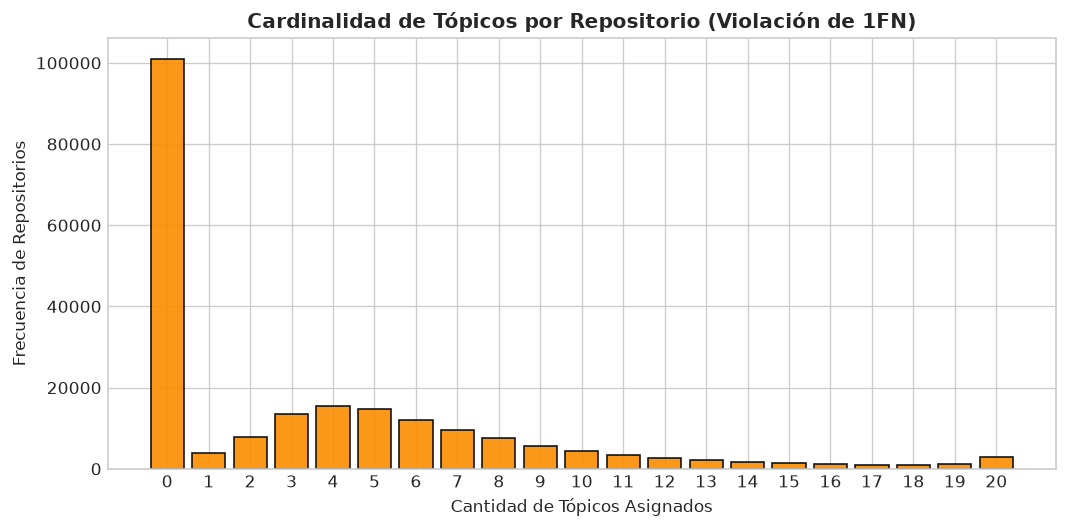

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
topics_counts = df['cant_topics'].value_counts().sort_index()
ax.bar(topics_counts.index, topics_counts.values, color='#fb8c00', edgecolor='black', alpha=0.9)
ax.set_title('Cardinalidad de Tópicos por Repositorio (Violación de 1FN)', fontsize=12, fontweight='bold')
ax.set_xlabel('Cantidad de Tópicos Asignados')
ax.set_ylabel('Frecuencia de Repositorios')
ax.set_xticks(range(0, 21))
plt.tight_layout()
plt.show()

**Conclusiones sobre Campos Semi-Estructurados (1FN):**
- **Distribución de Etiquetas:** El 47% de los repositorios no define tópicos (`[]`), mientras que el 53% define entre 1 y 20 etiquetas (mediana: 2, media: 3.59).
- **Violación de la 1FN:** Almacenar listas de tópicos dentro de un campo de texto plano impide realizar búsquedas indexadas eficientes, consultas relacionales directas (`JOIN`) y cálculos de co-ocurrencia sin un costoso análisis sintáctico por expresiones regulares.
- **Normalización Requerida:** Se debe implementar una relación de muchos a muchos (N:M):
  - `topics (id INT PRIMARY KEY, name VARCHAR(100) UNIQUE)`
  - `repository_topics (repository_id INT, topic_id INT, PRIMARY KEY (repository_id, topic_id))`

## 9. Distribución Tecnológica: Lenguajes de Programación y Licencias de Software
Evaluamos los lenguajes dominantes y los esquemas de licenciamiento de código abierto.

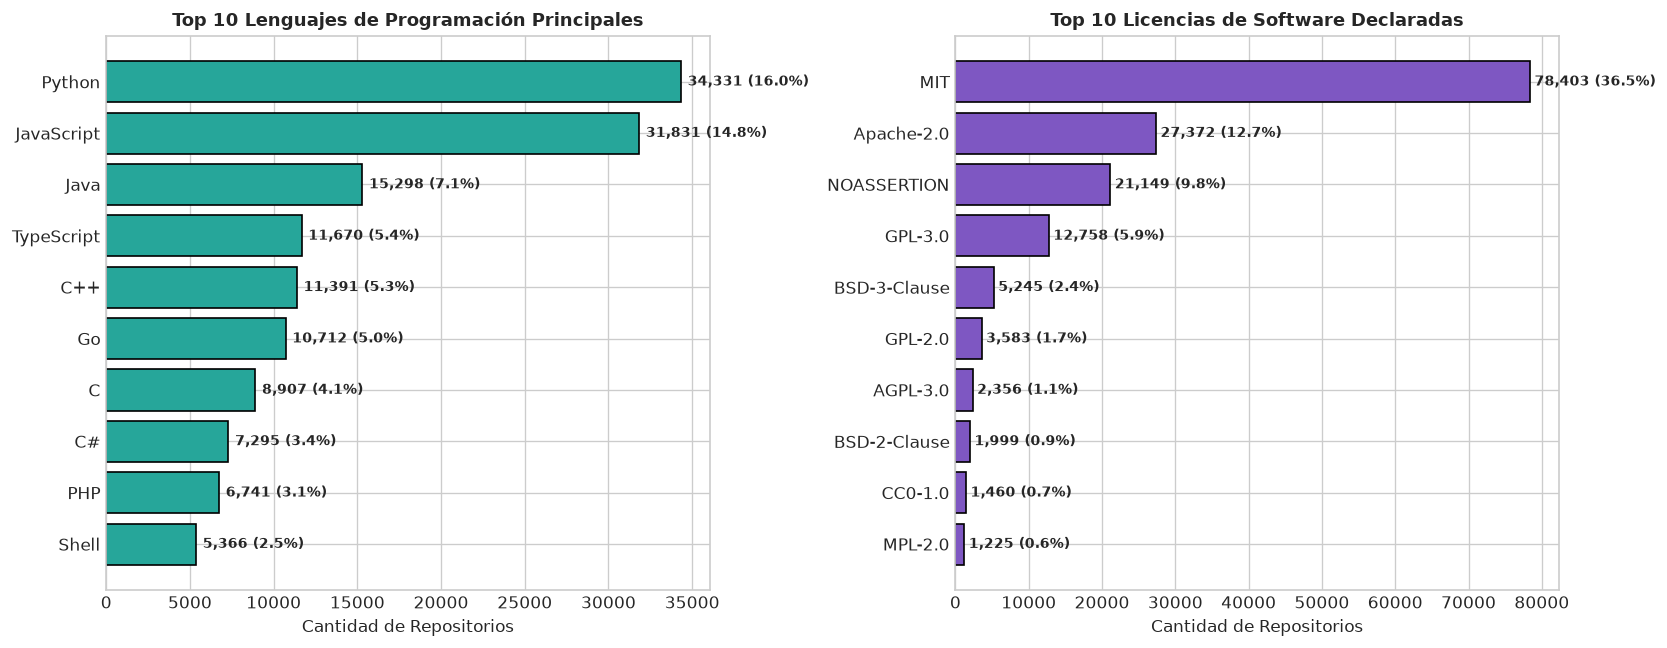

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
top_lang = df['Language'].value_counts().head(10).sort_values(ascending=True)
ax1.barh(top_lang.index, top_lang.values, color='#26a69a', edgecolor='black')
ax1.set_title('Top 10 Lenguajes de Programación Principales', fontsize=11, fontweight='bold')
ax1.set_xlabel('Cantidad de Repositorios')
for i, v in enumerate(top_lang.values):
    ax1.text(v + 400, i, f"{v:,} ({v/len(df)*100:.1f}%)", va='center', fontsize=8.5, fontweight='bold')

top_lic = df['License'].value_counts().head(10).sort_values(ascending=True)
ax2.barh(top_lic.index, top_lic.values, color='#7e57c2', edgecolor='black')
ax2.set_title('Top 10 Licencias de Software Declaradas', fontsize=11, fontweight='bold')
ax2.set_xlabel('Cantidad de Repositorios')
for i, v in enumerate(top_lic.values):
    ax2.text(v + 600, i, f"{v:,} ({v/len(df)*100:.1f}%)", va='center', fontsize=8.5, fontweight='bold')
plt.tight_layout()
plt.show()

**Conclusiones Tecnológicas y de Licenciamiento:**
- **Dominio de Python y JavaScript:** Python encabeza con **34,331 repositorios (16.0%)**, seguido de cerca por JavaScript con **31,831 (14.8%)**. Entre ambos representan casi un tercio de todo el ecosistema analizado.
- **Predominio de Licencias Permisivas:** La licencia **MIT** es ampliamente dominante con **78,403 repositorios (36.5%)**, seguida por **Apache-2.0 (12.7%)**. Esto indica una fuerte preferencia de la comunidad por licencias de código abierto con mínimas restricciones de distribución.

## 10. Conclusiones Integrales y Recomendaciones para Diseño de Base de Datos

### Resumen Ejecutivo de Hallazgos y Arquitectura de Datos
1. **Integridad de Claves Primarias y Subrogadas:**
   - La columna `URL` identifica de manera unívoca a los 215,029 repositorios (clave candidata natural).
   - La columna `Name` presenta 27,952 colisiones de nombres genéricos (`dotfiles`, `blog`, `docs`, `core`). Por ende, **nunca debe definirse con restricción `UNIQUE`**.
   - En el modelo físico relacional se debe implementar una clave subrogada artificial: `id SERIAL PRIMARY KEY`.
2. **Eliminación de Redundancia Físico-Lógica:**
   - `Stars` y `Watchers` replican idénticos valores en el 100% de los registros. Se debe conservar exclusivamente `stars` y eliminar `watchers` de la tabla física para ahorrar espacio en disco e índices redundantes.
   - `Is Fork` presenta varianza cero (100% False); en un Data Warehouse analítico puede omitirse o tratarse como metadata de ingestión.
3. **Normalización Relacional (Solución a Violaciones de 1FN):**
   - El atributo `Topics` contiene arrays serializados que violan la Primera Forma Normal.
   - Se debe desacoplar mediante el esquema clásico N:M:
     - `repository (id, name, url, created_at, updated_at, size, stars, forks, issues, language_id, license_id)`
     - `languages (id, name)`
     - `licenses (id, name)`
     - `topics (id, name)`
     - `repository_topics (repository_id, topic_id)`
4. **Tratamiento de Columnas Dispersas (*Sparse*) y Tipos de Datos:**
   - `Homepage` posee 63.5% de nulos: debe definirse como campo opcional (`VARCHAR(500) NULL`).
   - `Size` debe declararse como `BIGINT` en motores SQL para prevenir desbordamientos aritméticos frente a repositorios con decenas de gigabytes.
5. **Estrategia de Indexación Recomendada:**
   - Índices B-Tree en `language_id`, `created_at` y `stars` para acelerar consultas frecuentes de filtrado y ordenamiento en tableros analíticos o dashboards de BI.